In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch, FontManager, Sbopen
from matplotlib import rcParams

In [2]:
data = pd.read_csv("1874553_dynamic_events.csv")

In [3]:
data.head()

,event_id,index,match_id,frame_start,frame_end,frame_physical_start,time_start,time_end,minute_start,second_start,...,possession_epv_against_start,possession_epv_against_end,pass_reception_epv_for,pass_reception_epv_against,possession_epv_total,pass_epv_total,possession_epv_delta_for,possession_epv_delta_against,pass_epv_delta_for,pass_epv_delta_against
0,8_0,0,1874553,29,29,NaN,00:01.9,00:01.9,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1_0,1,1874553,32,54,NaN,00:02.2,00:04.4,0,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8_1,2,1874553,42,60,NaN,00:03.2,00:05.0,0,3,...,NaN,NaN,0.0247,0.0158,NaN,NaN,NaN,NaN,NaN,NaN
3,7_0,3,1874553,42,45,NaN,00:03.2,00:03.5,0,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7_1,4,1874553,42,54,NaN,00:03.2,00:04.4,0,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
data.shape

(4915, 322)

In [5]:
brisbane_data = data[data["team_shortname"] == 'Brisbane FC']

In [6]:
brisbane_data.nunique()

event_id                        2097
index                           2097
match_id                           1
frame_start                     1416
frame_end                       1175
                                ... 
pass_epv_total                   182
possession_epv_delta_for         144
possession_epv_delta_against      78
pass_epv_delta_for               161
pass_epv_delta_against            88
Length: 322, dtype: int64

In [7]:
brisbane_data

,event_id,index,match_id,frame_start,frame_end,frame_physical_start,time_start,time_end,minute_start,second_start,...,possession_epv_against_start,possession_epv_against_end,pass_reception_epv_for,pass_reception_epv_against,possession_epv_total,pass_epv_total,possession_epv_delta_for,possession_epv_delta_against,pass_epv_delta_for,pass_epv_delta_against
0,8_0,0,1874553,29,29,NaN,00:01.9,00:01.9,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1_0,1,1874553,32,54,NaN,00:02.2,00:04.4,0,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8_1,2,1874553,42,60,NaN,00:03.2,00:05.0,0,3,...,NaN,NaN,0.0247,0.0158,NaN,NaN,NaN,NaN,NaN,NaN
3,7_0,3,1874553,42,45,NaN,00:03.2,00:03.5,0,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7_1,4,1874553,42,54,NaN,00:03.2,00:04.4,0,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4907,8_956,4907,1874553,59735,59735,NaN,96:13.5,96:13.5,96,13,...,0.0148,0.0148,0.0450,0.0147,0.0000,0.0125,0.0000,0.0000,0.0124,-0.0001
4908,7_2541,4908,1874553,59735,59735,NaN,96:13.5,96:13.5,96,13,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4909,8_957,4909,1874553,59755,59788,NaN,96:15.5,96:18.8,96,15,...,0.0147,0.0134,NaN,NaN,0.0335,NaN,0.0322,-0.0013,NaN,NaN
4910,1_534,4910,1874553,59759,59774,NaN,96:15.9,96:17.4,96,15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
individual_player_events = brisbane_data.groupby("player_position_id")["event_id"].count()

In [9]:
individual_player_events

player_position_id
1      53
2     143
4     125
6     139
8     155
9     218
11    220
15    244
16    255
17    268
19    277
Name: event_id, dtype: int64

In [10]:
goalkeeper_events = brisbane_data[data["player_position_id"] == 1]

In [11]:
goalkeeper_events

,event_id,index,match_id,frame_start,frame_end,frame_physical_start,time_start,time_end,minute_start,second_start,...,possession_epv_against_start,possession_epv_against_end,pass_reception_epv_for,pass_reception_epv_against,possession_epv_total,pass_epv_total,possession_epv_delta_for,possession_epv_delta_against,pass_epv_delta_for,pass_epv_delta_against
27,7_9,27,1874553,257,273,NaN,00:24.7,00:26.3,0,24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,7_11,32,1874553,291,297,NaN,00:28.1,00:28.7,0,28,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
234,7_109,234,1874553,2898,2922,NaN,04:48.8,04:51.2,4,48,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
237,8_50,237,1874553,2939,2955,NaN,04:52.9,04:54.5,4,52,...,0.0240,0.0216,0.0136,0.0343,0.0013,-0.0171,-0.0010,-0.0024,-0.0044,0.0127
249,8_52,249,1874553,3042,3068,NaN,05:03.2,05:05.8,5,3,...,0.0491,0.0206,NaN,NaN,0.0314,NaN,0.0029,-0.0285,NaN,NaN
319,8_63,319,1874553,4334,4421,NaN,07:12.4,07:21.1,7,12,...,0.0853,0.0174,0.0262,0.0151,0.0744,0.0065,0.0065,-0.0679,0.0042,-0.0023
493,7_246,493,1874553,5377,5387,NaN,08:56.7,08:57.7,8,56,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
593,7_299,593,1874553,5985,5987,NaN,09:57.5,09:57.7,9,57,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
595,8_115,595,1874553,6002,6015,NaN,09:59.2,10:00.5,9,59,...,NaN,NaN,0.0273,0.0148,NaN,NaN,NaN,NaN,NaN,NaN
873,8_171,873,1874553,10702,10751,NaN,17:49.2,17:54.1,17,49,...,0.0216,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
goalkeeper_events.nunique()

event_id                        53
index                           53
match_id                         1
frame_start                     53
frame_end                       53
                                ..
pass_epv_total                  10
possession_epv_delta_for        11
possession_epv_delta_against    11
pass_epv_delta_for              10
pass_epv_delta_against           9
Length: 322, dtype: int64

In [13]:
goalkeeper_events.nunique()

event_id                        53
index                           53
match_id                         1
frame_start                     53
frame_end                       53
                                ..
pass_epv_total                  10
possession_epv_delta_for        11
possession_epv_delta_against    11
pass_epv_delta_for              10
pass_epv_delta_against           9
Length: 322, dtype: int64

In [14]:
key_metrics = ["event_id","index","match_id","frame_start","frame_end","frame_physical_start","time_start","time_end","period","attacking_side_id","attacking_side","event_type_id","event_type","player_id","player_name","player_position","player_in_possession_id","player_in_possession_name","player_in_possession_position_id","player_in_possession_position","x_start","y_start","channel_id_start","x_end","y_end"]

In [15]:
goalkeeper_events = goalkeeper_events[key_metrics]

In [16]:
goalkeeper_events = goalkeeper_events.drop("match_id",axis=1)

In [17]:
goalkeeper_events = goalkeeper_events.drop("frame_physical_start",axis=1)

In [18]:
goalkeeper_events

,event_id,index,frame_start,frame_end,time_start,time_end,period,attacking_side_id,attacking_side,event_type_id,...,player_position,player_in_possession_id,player_in_possession_name,player_in_possession_position_id,player_in_possession_position,x_start,y_start,channel_id_start,x_end,y_end
27,7_9,27,257,273,00:24.7,00:26.3,1,1,left_to_right,7,...,GK,69111.0,H. Bility,6.0,RCB,-37.48,-11.28,4,-41.62,-8.66
32,7_11,32,291,297,00:28.1,00:28.7,1,1,left_to_right,7,...,GK,287934.0,Walid Shour,9.0,LDM,-42.30,-5.47,3,-41.98,-5.17
234,7_109,234,2898,2922,04:48.8,04:51.2,1,1,left_to_right,7,...,GK,69111.0,H. Bility,6.0,RCB,-37.35,-11.30,4,-45.63,-11.67
237,8_50,237,2939,2955,04:52.9,04:54.5,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,-48.01,-7.50,3,-47.51,-3.09
249,8_52,249,3042,3068,05:03.2,05:05.8,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,-52.58,10.88,2,-53.22,12.14
319,8_63,319,4334,4421,07:12.4,07:21.1,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,-51.94,6.64,3,-38.33,4.05
493,7_246,493,5377,5387,08:56.7,08:57.7,1,1,left_to_right,7,...,GK,50973.0,J. Caletti,11.0,RDM,-35.25,0.37,3,-35.62,-0.16
593,7_299,593,5985,5987,09:57.5,09:57.7,1,1,left_to_right,7,...,GK,51050.0,B. Warland,4.0,LCB,-30.86,4.52,3,-30.93,4.42
595,8_115,595,6002,6015,09:59.2,10:00.5,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,-31.42,3.16,3,-31.75,1.82
873,8_171,873,10702,10751,17:49.2,17:54.1,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,-49.19,14.16,2,-47.46,12.14


In [19]:
goalkeeper_events.nunique()

event_id                            53
index                               53
frame_start                         53
frame_end                           53
time_start                          53
time_end                            53
period                               2
attacking_side_id                    2
attacking_side                       2
event_type_id                        2
event_type                           2
player_id                            1
player_name                          1
player_position                      1
player_in_possession_id              8
player_in_possession_name            8
player_in_possession_position_id     7
player_in_possession_position        7
x_start                             51
y_start                             51
channel_id_start                     3
x_end                               51
y_end                               50
dtype: int64

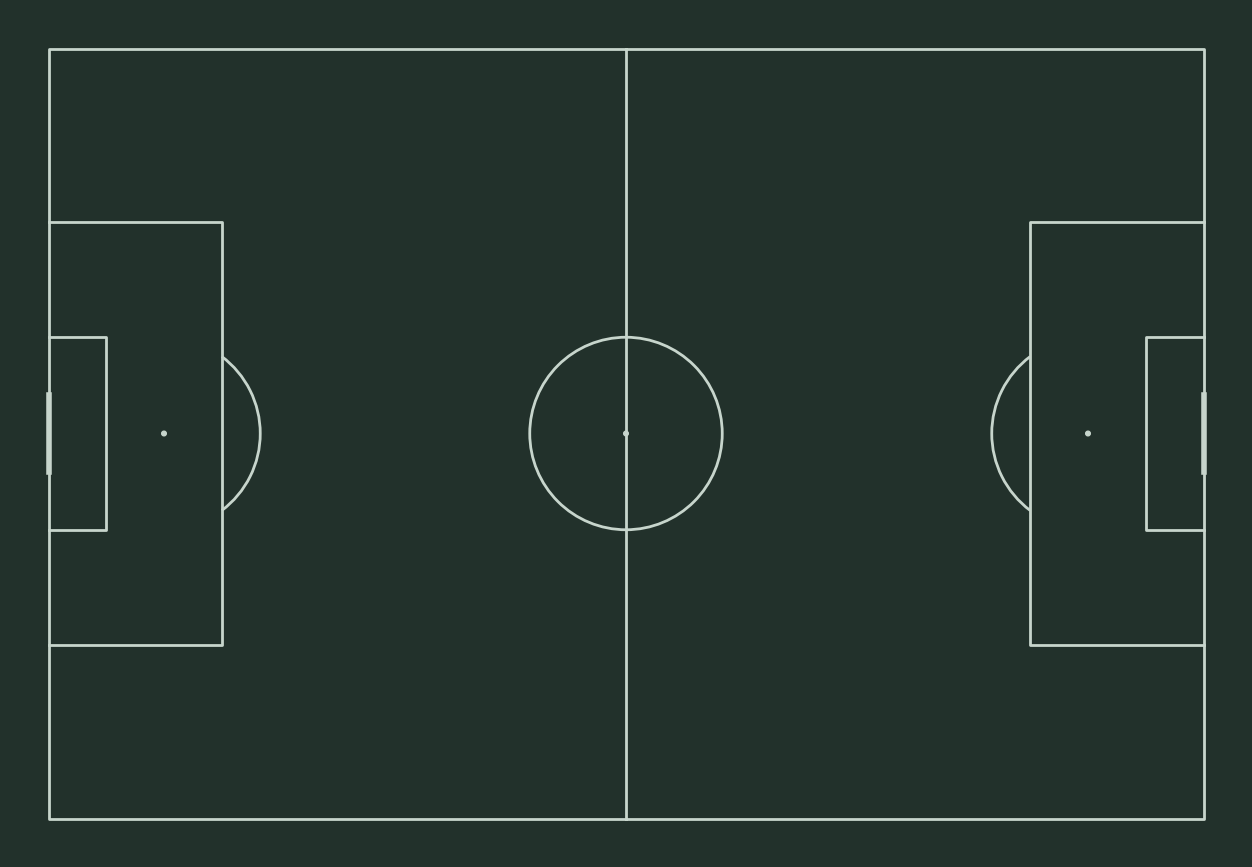

In [20]:
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('#22312b')

pitch.arrows(goalkeeper_events["x_start"], goalkeeper_events["y_start"],
             goalkeeper_events["x_end"], goalkeeper_events["y_end"], width=2,
             headwidth=10, headlength=10, color='#ad993c', ax=ax, label='completed passes')

In [21]:
goalkeeper_events["x_start"] = goalkeeper_events["x_start"]+60
goalkeeper_events["x_start"]

27      22.52
32      17.70
234     22.65
237     11.99
249      7.42
319      8.06
493     24.75
593     29.14
595     28.58
873     10.81
877     20.15
1652    18.50
1653    19.79
1657    20.46
1712     8.62
1713      NaN
1720      NaN
1816    31.62
1820    34.17
1826    34.18
1844    24.46
1847    25.79
2102    28.83
2103    27.56
2115    21.96
2774    11.59
2911    29.13
2917    22.83
2959    18.33
2965     9.55
3077    18.70
3083    15.87
3087    14.24
3094    11.54
3330    10.86
3495    19.53
3550    21.48
4001    18.63
4006    11.05
4076    12.79
4098    19.39
4101    19.41
4116    12.83
4238    10.68
4240    18.92
4257    20.35
4282    17.33
4290    23.98
4292    22.60
4501    20.72
4509    18.86
4572    36.90
4780    24.89
Name: x_start, dtype: float64

In [22]:
goalkeeper_events["x_end"] = goalkeeper_events["x_end"]+60
goalkeeper_events["x_end"]

27      18.38
32      18.02
234     14.37
237     12.49
249      6.78
319     21.67
493     24.38
593     29.07
595     28.25
873     12.54
877     21.89
1652    18.69
1653    20.38
1657    20.44
1712    10.21
1713      NaN
1720      NaN
1816    33.14
1820    34.17
1826    34.18
1844    24.77
1847    26.10
2102    28.64
2103    26.12
2115    21.61
2774    11.58
2911    25.37
2917    21.32
2959     9.91
2965     9.55
3077    21.45
3083    15.29
3087    13.97
3094    10.91
3330    10.73
3495    12.40
3550    21.48
4001    18.63
4006    11.05
4076    12.88
4098    19.12
4101    19.05
4116    12.03
4238    19.39
4240    17.05
4257    21.05
4282    22.00
4290    23.32
4292    21.94
4501    19.16
4509    18.88
4572    36.00
4780    25.90
Name: x_end, dtype: float64

In [23]:
goalkeeper_events["y_end"] = goalkeeper_events["y_end"]+40
goalkeeper_events["y_end"]

27      31.34
32      34.83
234     28.33
237     36.91
249     52.14
319     44.05
493     39.84
593     44.42
595     41.82
873     52.14
877     42.47
1652    41.01
1653    41.29
1657    41.09
1712    36.36
1713      NaN
1720      NaN
1816    34.59
1820    34.22
1826    33.63
1844    41.45
1847    40.20
2102    37.11
2103    38.61
2115    34.02
2774    40.54
2911    37.14
2917    38.09
2959    28.29
2965    27.83
3077    32.61
3083    45.30
3087    46.86
3094    39.49
3330    40.51
3495    41.85
3550    47.39
4001    38.95
4006    42.89
4076    41.56
4098    33.62
4101    38.79
4116    53.35
4238    39.76
4240    42.45
4257    46.62
4282    46.90
4290    41.86
4292    51.09
4501    43.53
4509    43.36
4572    41.38
4780    36.59
Name: y_end, dtype: float64

In [24]:
goalkeeper_events["y_start"] = goalkeeper_events["y_start"]+40
goalkeeper_events["y_start"]

27      28.72
32      34.53
234     28.70
237     32.50
249     50.88
319     46.64
493     40.37
593     44.52
595     43.16
873     54.16
877     37.43
1652    40.97
1653    41.14
1657    41.07
1712    35.94
1713      NaN
1720      NaN
1816    34.94
1820    34.22
1826    33.63
1844    41.42
1847    40.89
2102    36.97
2103    38.01
2115    34.32
2774    40.71
2911    37.04
2917    38.09
2959    35.38
2965    27.83
3077    29.79
3083    43.81
3087    46.88
3094    41.90
3330    40.44
3495    47.82
3550    47.39
4001    38.95
4006    42.89
4076    41.40
4098    32.79
4101    37.26
4116    50.92
4238    44.08
4240    40.40
4257    46.43
4282    43.64
4290    42.41
4292    46.93
4501    43.76
4509    43.49
4572    41.80
4780    36.30
Name: y_start, dtype: float64

In [25]:
goalkeeper_events

,event_id,index,frame_start,frame_end,time_start,time_end,period,attacking_side_id,attacking_side,event_type_id,...,player_position,player_in_possession_id,player_in_possession_name,player_in_possession_position_id,player_in_possession_position,x_start,y_start,channel_id_start,x_end,y_end
27,7_9,27,257,273,00:24.7,00:26.3,1,1,left_to_right,7,...,GK,69111.0,H. Bility,6.0,RCB,22.52,28.72,4,18.38,31.34
32,7_11,32,291,297,00:28.1,00:28.7,1,1,left_to_right,7,...,GK,287934.0,Walid Shour,9.0,LDM,17.70,34.53,3,18.02,34.83
234,7_109,234,2898,2922,04:48.8,04:51.2,1,1,left_to_right,7,...,GK,69111.0,H. Bility,6.0,RCB,22.65,28.70,4,14.37,28.33
237,8_50,237,2939,2955,04:52.9,04:54.5,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,11.99,32.50,3,12.49,36.91
249,8_52,249,3042,3068,05:03.2,05:05.8,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,7.42,50.88,2,6.78,52.14
319,8_63,319,4334,4421,07:12.4,07:21.1,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,8.06,46.64,3,21.67,44.05
493,7_246,493,5377,5387,08:56.7,08:57.7,1,1,left_to_right,7,...,GK,50973.0,J. Caletti,11.0,RDM,24.75,40.37,3,24.38,39.84
593,7_299,593,5985,5987,09:57.5,09:57.7,1,1,left_to_right,7,...,GK,51050.0,B. Warland,4.0,LCB,29.14,44.52,3,29.07,44.42
595,8_115,595,6002,6015,09:59.2,10:00.5,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,28.58,43.16,3,28.25,41.82
873,8_171,873,10702,10751,17:49.2,17:54.1,1,1,left_to_right,8,...,GK,NaN,NaN,NaN,NaN,10.81,54.16,2,12.54,52.14


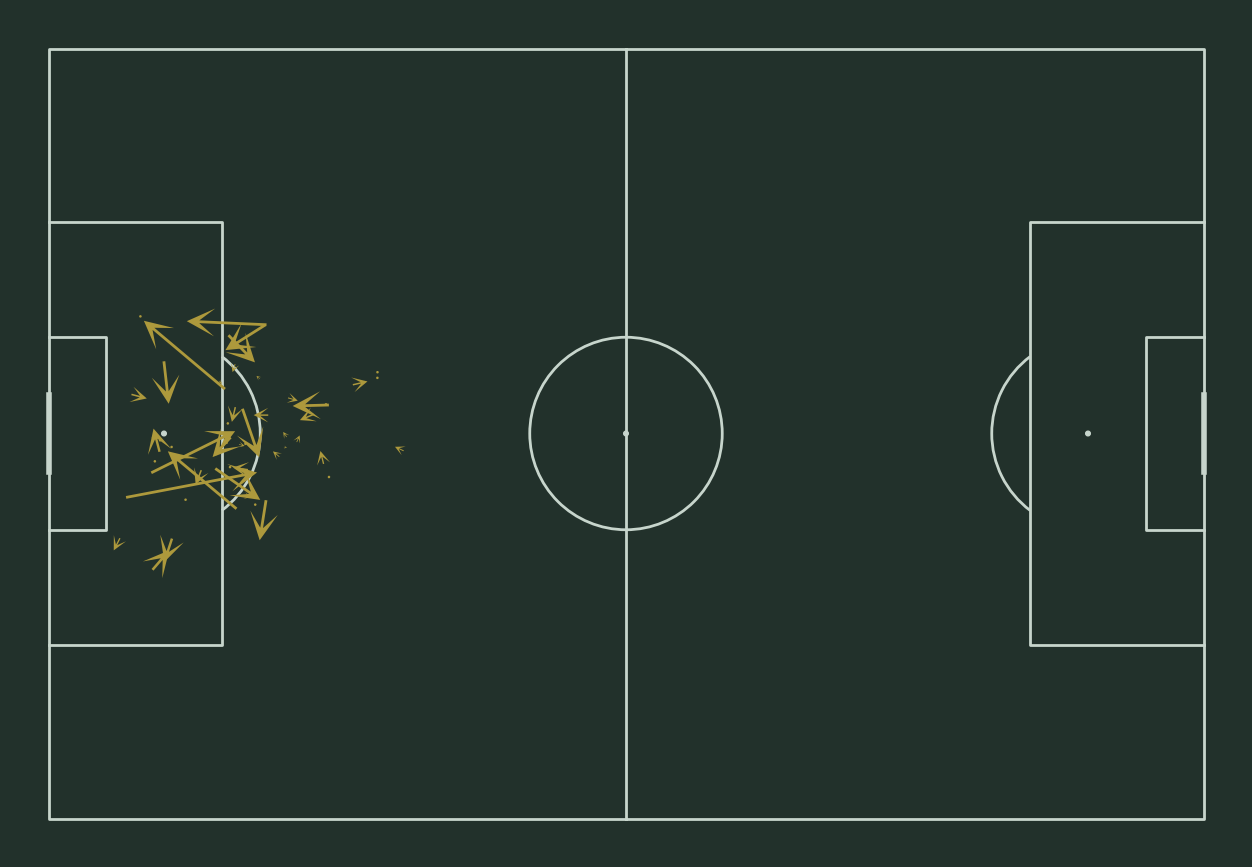

In [26]:
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('#22312b')

pitch.arrows(goalkeeper_events["x_start"], goalkeeper_events["y_start"],
             goalkeeper_events["x_end"], goalkeeper_events["y_end"], width=2,
             headwidth=10, headlength=10, color='#ad993c', ax=ax, label='completed passes')

# ax.legend(facecolor='#22312b', handlelength=5, edgecolor='None', fontsize=20, loc='upper left')